In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully.")

Libraries imported successfully.


In [12]:
import pandas as pd
import os

df = pd.read_csv("../data/raw/maize_yield_rwanda_rw.csv")

print("Original dataset shape:", df.shape)
df.head()

Original dataset shape: (1426, 20)


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,NaN,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


In [13]:
# Make a copy of the original dataset
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Remove rows where the target value is missing
clean_df = clean_df.dropna(subset=["yield_t_ha"])

# Display cleaned dataset information
print("Cleaned dataset shape:", clean_df.shape)
print("Remaining missing values:")
print(clean_df.isnull().sum())

Cleaned dataset shape: (1426, 20)
Remaining missing values:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64


In [14]:
# Make a copy of the original dataset
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Remove rows where the target value is missing
clean_df = clean_df.dropna(subset=["yield_t_ha"])

# Display cleaned dataset information
print("Cleaned dataset shape:", clean_df.shape)
print("Remaining missing values:")
print(clean_df.isnull().sum())

Cleaned dataset shape: (1426, 20)
Remaining missing values:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64


In [15]:
# Make a copy of the original dataset
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Remove rows where the target value is missing
clean_df = clean_df.dropna(subset=["yield_t_ha"])

# Display cleaned dataset information
print("Cleaned dataset shape:", clean_df.shape)
print("Remaining missing values:")
print(clean_df.isnull().sum())

Cleaned dataset shape: (1426, 20)
Remaining missing values:
record_id                0
year                     0
season                   0
province                 0
district                 0
altitude_m               0
rainfall_mm             11
avg_temp_c               0
soil_ph                 14
soil_type                0
seed_variety             0
farming_practice         0
npk_kg_ha                0
urea_kg_ha               0
manure_t_ha              0
plant_density_per_ha     0
farm_area_ha             0
irrigation               0
pest_incidence_index    14
yield_t_ha               0
dtype: int64


In [16]:
# Create interim folder if it does not exist
os.makedirs("../data/interim", exist_ok=True)

# Save cleaned dataset
clean_df.to_csv(
    "../data/interim/maize_yield_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [17]:
import os

file_path = "../data/interim/maize_yield_clean.csv"

print("File exists:", os.path.exists(file_path))

File exists: True


In [18]:
# Load cleaned dataset
df = pd.read_csv("../data/interim/maize_yield_clean.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (1426, 20)


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,NaN,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


In [19]:
# Feature 1: Rainfall efficiency
if "rainfall_mm" in df.columns and "temperature_c" in df.columns:
    df["rainfall_temperature_ratio"] = (
        df["rainfall_mm"] / (df["temperature_c"].abs() + 1)
    )

# Feature 2: Soil fertility indicator
if "soil_ph" in df.columns:
    df["soil_ph_difference"] = abs(df["soil_ph"] - 6.5)

# Feature 3: Rainfall category
if "rainfall_mm" in df.columns:
    df["rainfall_category"] = pd.cut(
        df["rainfall_mm"],
        bins=[-np.inf, 500, 1000, 1500, np.inf],
        labels=["Low", "Moderate", "High", "Very High"]
    )

# Feature 4: Temperature category
if "temperature_c" in df.columns:
    df["temperature_category"] = pd.cut(
        df["temperature_c"],
        bins=[-np.inf, 15, 25, 30, np.inf],
        labels=["Cold", "Moderate", "Warm", "Hot"]
    )

# Feature 5: Pest risk category
if "pest_incidence_index" in df.columns:
    df["pest_risk_category"] = pd.cut(
        df["pest_incidence_index"],
        bins=[-np.inf, 2, 5, np.inf],
        labels=["Low", "Medium", "High"]
    )

print("New features created successfully.")
display(df.head())

New features created successfully.


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,...,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha,soil_ph_difference,rainfall_category,pest_risk_category
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,...,57.4,1.41,61803,0.63,No,NaN,2.71,NaN,NaN,NaN
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,...,62.7,3.69,52919,0.17,No,0.339,4.09,0.48,Low,Low
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,...,50.7,5.18,54406,0.22,No,0.049,2.58,0.77,Moderate,Low
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,...,60.4,1.68,48119,0.48,No,0.171,2.45,1.30,Moderate,Low
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,...,70.4,0.36,56787,1.16,No,0.001,2.09,0.58,Moderate,Low


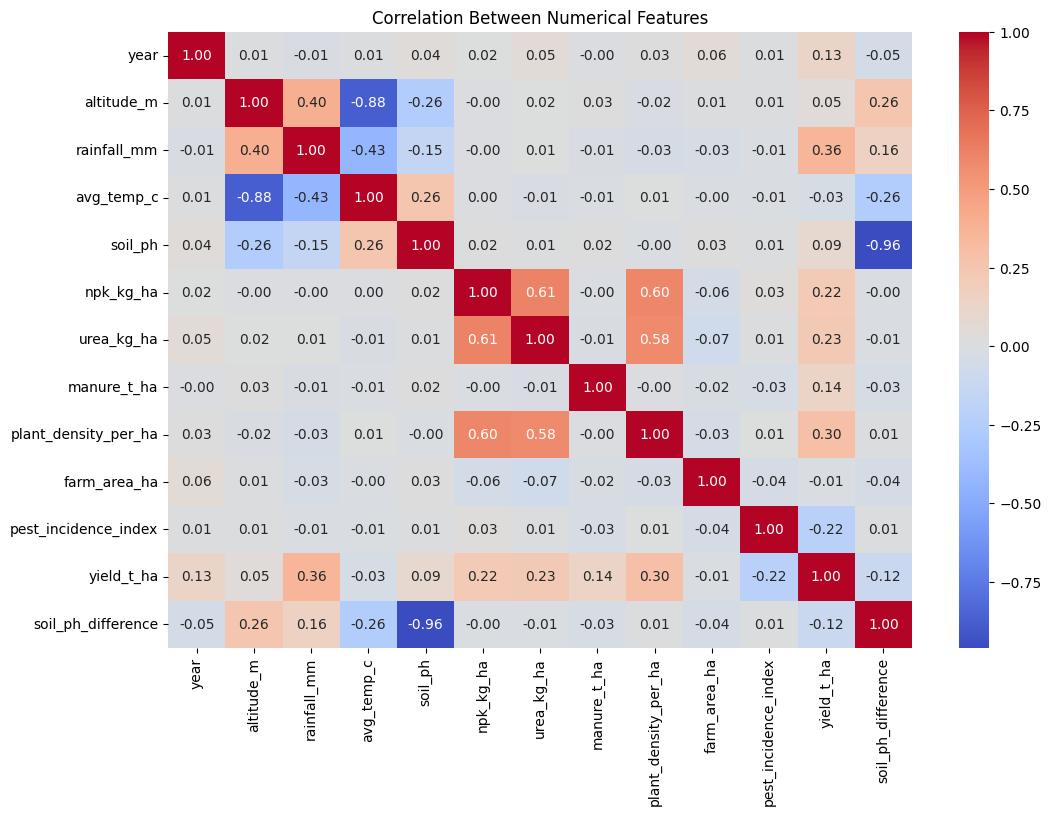

In [20]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Numerical Features")
plt.show()

,Feature,Importance
2,rainfall_mm,0.234320
8,plant_density_per_ha,0.152679
10,pest_incidence_index,0.124243
7,manure_t_ha,0.068879
6,urea_kg_ha,0.062409
9,farm_area_ha,0.058329
5,npk_kg_ha,0.055673
1,altitude_m,0.052735
3,avg_temp_c,0.051320
4,soil_ph,0.047962


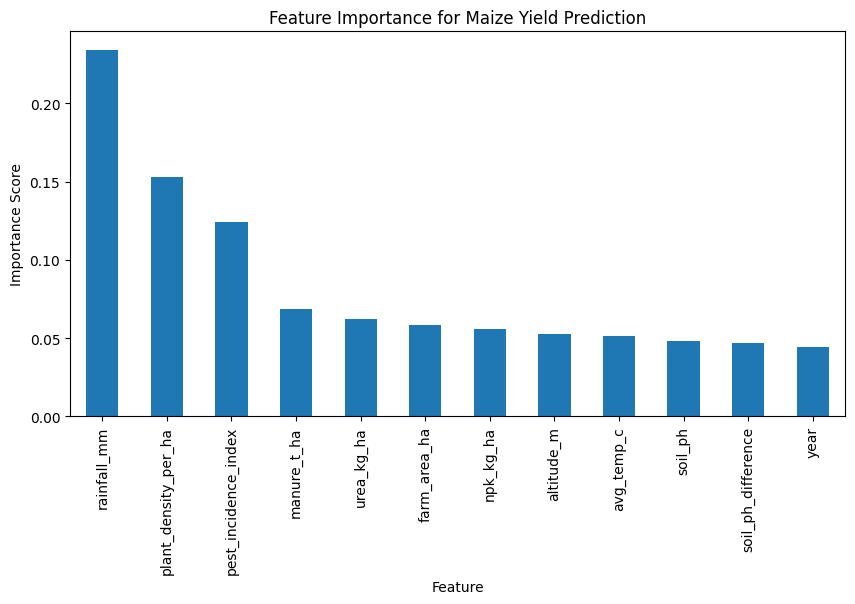

In [21]:
target = "yield_t_ha"

X = df.drop(columns=[target, "record_id"], errors="ignore")
y = df[target]

# Use numerical features for this initial importance analysis
X_numeric = X.select_dtypes(include=np.number)

# Handle missing values for the analysis
X_numeric = X_numeric.fillna(X_numeric.median())

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_numeric, y)

importance = pd.DataFrame({
    "Feature": X_numeric.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Feature Importance for Maize Yield Prediction")
plt.ylabel("Importance Score")
plt.show()

In [22]:
selector = SelectKBest(
    score_func=f_regression,
    k=min(10, X_numeric.shape[1])
)

selector.fit(X_numeric, y)

selected_features = X_numeric.columns[
    selector.get_support()
]

print("Selected features:")
print(list(selected_features))

Selected features:
['year', 'altitude_m', 'rainfall_mm', 'soil_ph', 'npk_kg_ha', 'urea_kg_ha', 'manure_t_ha', 'plant_density_per_ha', 'pest_incidence_index', 'soil_ph_difference']


In [23]:
feature_justification = pd.DataFrame({
    "Feature": [
        "rainfall_temperature_ratio",
        "soil_ph_difference",
        "rainfall_category",
        "temperature_category",
        "pest_risk_category"
    ],
    "Purpose": [
        "Examines rainfall relative to temperature.",
        "Measures soil pH distance from 6.5.",
        "Groups rainfall into categories.",
        "Groups temperature into categories.",
        "Groups pest incidence into risk levels."
    ],
    "Reason": [
        "May help identify climate conditions affecting yield.",
        "May help assess soil suitability.",
        "Makes rainfall patterns easier to interpret.",
        "Makes temperature patterns easier to compare.",
        "Helps examine the effect of pest pressure."
    ]
})

display(feature_justification)

feature_justification.to_csv(
    "../docs/feature_justification.csv",
    index=False
)

,Feature,Purpose,Reason
0,rainfall_temperature_ratio,Examines rainfall relative to temperature.,May help identify climate conditions affecting...
1,soil_ph_difference,Measures soil pH distance from 6.5.,May help assess soil suitability.
2,rainfall_category,Groups rainfall into categories.,Makes rainfall patterns easier to interpret.
3,temperature_category,Groups temperature into categories.,Makes temperature patterns easier to compare.
4,pest_risk_category,Groups pest incidence into risk levels.,Helps examine the effect of pest pressure.


In [24]:
os.makedirs("../data/processed", exist_ok=True)

df.to_csv(
    "../data/processed/maize_yield_engineered.csv",
    index=False
)

print("Engineered dataset saved successfully.")

Engineered dataset saved successfully.


In [25]:
import os

print(os.listdir("../data/processed"))

['maize_yield_engineered.csv', 'preprocessing_pipeline.pkl', 'X_test.csv', 'X_train.csv', 'X_validation.csv', 'y_test.csv', 'y_train.csv', 'y_validation.csv']


In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/processed/maize_yield_engineered.csv")

X = df.drop(columns=["yield_t_ha", "record_id"], errors="ignore")
y = df["yield_t_ha"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1426, 21)
Target: (1426,)


In [27]:
# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (998, 21)
Validation: (214, 21)
Testing: (214, 21)


In [28]:
import os

os.makedirs("../data/processed", exist_ok=True)

train_df = X_train.copy()
train_df["yield_t_ha"] = y_train

val_df = X_val.copy()
val_df["yield_t_ha"] = y_val

test_df = X_test.copy()
test_df["yield_t_ha"] = y_test

train_df.to_csv("../data/processed/train.csv", index=False)
val_df.to_csv("../data/processed/validation.csv", index=False)
test_df.to_csv("../data/processed/test.csv", index=False)

print("All datasets saved successfully!")

All datasets saved successfully!


In [29]:
print(os.listdir("../data/processed"))

['maize_yield_engineered.csv', 'preprocessing_pipeline.pkl', 'test.csv', 'train.csv', 'validation.csv', 'X_test.csv', 'X_train.csv', 'X_validation.csv', 'y_test.csv', 'y_train.csv', 'y_validation.csv']
